# MiInflación · EDA del IPC nacional

**Actividad 1 · Python, fuentes de datos, EDA y limpieza.** Este cuaderno comprueba si la muestra del INE permite comparar la evolución mensual de los precios de seis grupos de consumo en MiInflación. Sigue el enunciado de la Actividad 1 (pp. 6–8), la sesión 01 «Del producto a los datos» (diapositivas 11–24) y la [definición del proyecto](../README.md). Las transformaciones son diagnósticas y se realizan en memoria. La capa Bronze se lee como archivo de origen y la construcción de Silver queda fuera de este cuaderno.

## 1. Fuente y reproducción

- **Proveedor y acceso.** Instituto Nacional de Estadística (INE), tabla 76125, «Índices nacionales: general y de grupos ECOICOP ver.2», IPC base 2025. La publicación es mensual. Para la muestra, la última actualización de la tabla indicada por INEbase es el **13/11/2026**, con consulta documentada el **22/11/2026**. Octubre de 2026, por ejemplo, se publica en noviembre. [Tabla 76125](https://www.ine.es/jaxiT3/Tabla.htm?t=76125) · [Resultados nacionales, base 2025](https://www.ine.es/dynt3/inebase/index.htm?capsel=12766&padre=12764).
- **Población, detalle y privacidad.** Cada fila representa una observación mensual de un grupo de consumo, para España en su conjunto y un tipo de dato. Los índices son agregados y carecen de registros de personas, compras y presupuestos. La periodicidad permite comparaciones mensuales de la cesta del producto. Para personalizarlas seguirán haciendo falta los importes de gasto del hogar.
- **Reutilización.** El INE establece como licencia general para sus estadísticas CC BY 4.0, salvo indicación específica. Permite copiar, publicar y transformar la muestra con atribución. Los resultados de este cuaderno son elaboración propia con datos extraídos del sitio web del INE. [Aviso legal del INE](https://www.ine.es/aviso_legal/).

Para reconstruir la entrada, abre la tabla 76125 y selecciona los grupos **01, 02, 04, 07, 09 y 11** (Restaurantes y servicios de alojamiento puede aparecer como **011**), el tipo de dato **Índice** y los meses **2025M01–2026M10**, ambos incluidos. Descarga el CSV separado por punto y coma y guarda el original en `data/raw/ipc_nacional_2026-11-22.csv`. También puedes usar el [CSV completo](https://www.ine.es/jaxiT3/files/t/csv_bdsc/76125.csv), que el cuaderno filtra en memoria. Una nueva descarga puede tener otra huella o incorporar revisiones.


Abre la carpeta del proyecto en VS Code o JupyterLab y selecciona el kernel de Python de `.venv`. Instala las dependencias desde la raíz del repositorio y ejecuta todas las celdas. En Windows, con el entorno virtual creado:

~~~powershell
.\.venv\Scripts\python.exe -m pip install -r requirements.txt
~~~

El cuaderno busca `data/raw/ipc_nacional_2026-11-22.csv` desde el directorio de trabajo del kernel hacia sus carpetas superiores. Así funciona desde la raíz y desde `notebooks/`. Si el kernel se inicia fuera del proyecto, indica la ruta absoluta al CSV en `RUTA_CSV_MANUAL`, en la primera celda de código. La ejecución se verificó con Python 3.14.5.

In [3]:
# Importación de librerías
import csv
from hashlib import sha256
from io import StringIO
from pathlib import Path
import sys

from IPython.display import Markdown, display
import matplotlib as mpl
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
import numpy as np
import pandas as pd

Matplotlib is building the font cache; this may take a moment.


In [4]:
plt.switch_backend("module://matplotlib_inline.backend_inline")
set_matplotlib_formats("png")

GRUPOS = {
    "01": "Alimentos y bebidas no alcohólicas",
    "02": "Bebidas alcohólicas y tabaco",
    "04": "Vivienda, agua, electricidad, gas y otros combustibles",
    "07": "Transporte",
    "09": "Actividades recreativas, deporte y cultura",
    "11": "Restaurantes y servicios de alojamiento"
}

AMBITO, BASE_IPC, MEDIDA = "Nacional", 2025, "Índice"
MESES = pd.period_range("2025-01", "2026-10", freq="M", name="mes")
RUTA_RELATIVA = Path("data/raw/ipc_nacional_2026-11-22.csv")
RUTA_CSV_MANUAL = None  # Ruta absoluta al CSV si el kernel se inicia fuera del proyecto.
HUELLA_REFERENCIA = "b02a9bc4eacf303853d92a92dff02336342515bf61057491b87d95768db94ab9"
COLUMNAS = ["Grupos ECOICOP ver.2", "Tipo de dato", "Periodo", "Total"]

directorio_kernel = Path.cwd()

if RUTA_CSV_MANUAL is None:
    csv_path = next(
        (base / RUTA_RELATIVA for base in (directorio_kernel, *directorio_kernel.parents)
         if (base / RUTA_RELATIVA).is_file()),
        None,
    )
    if csv_path is None:
        raise FileNotFoundError(
            f"No se encontró {RUTA_RELATIVA.as_posix()} desde {directorio_kernel}. "
            "Abre la carpeta del proyecto o indica la ruta absoluta en RUTA_CSV_MANUAL."
        )
else:
    csv_path = Path(RUTA_CSV_MANUAL).expanduser()
    if not csv_path.is_absolute():
        raise ValueError("RUTA_CSV_MANUAL debe ser una ruta absoluta.")
    if not csv_path.is_file():
        raise FileNotFoundError(f"RUTA_CSV_MANUAL no apunta a un archivo: {csv_path}")

contenido = csv_path.read_bytes()
huella = sha256(contenido).hexdigest()

try:
    texto = contenido.decode("utf-8-sig")
    codificacion = "UTF-8 con BOM" if contenido.startswith(b"\xef\xbb\xbf") else "UTF-8"
except UnicodeDecodeError:
    texto = contenido.decode("cp1252")
    codificacion = "cp1252"

lector = csv.reader(StringIO(texto, newline=""), delimiter=";", strict=True)
cabecera = [campo.strip() for campo in next(lector, [])]
if sorted(cabecera) != sorted(COLUMNAS):
    raise ValueError(f"Cabecera inesperada para la tabla 76125 separada por ';': {cabecera!r}")

filas = []
lineas = []
for fila in lector:
    if not fila or (len(fila) == 1 and not fila[0].strip()):
        continue
    if len(fila) != len(cabecera):
        raise ValueError(f"Línea {lector.line_num}: se esperaban {len(cabecera)} campos y hay {len(fila)}.")
    filas.append(fila)
    lineas.append(lector.line_num)

bronze = pd.DataFrame(filas, columns=cabecera, dtype="string")
bronze.index = pd.Index(lineas, name="línea CSV")
bronze = bronze[COLUMNAS]

ruta_mostrada = RUTA_RELATIVA.as_posix() if RUTA_CSV_MANUAL is None else str(csv_path)
print(f"Archivo: {ruta_mostrada} | codificación: {codificacion}")
print(f"SHA-256: {huella} | muestra de referencia: {'sí' if huella == HUELLA_REFERENCIA else 'otra exportación'}")
print(f"Python {sys.version.split()[0]} · pandas {pd.__version__} · NumPy {np.__version__} · Matplotlib {mpl.__version__}")

Archivo: data/raw/ipc_nacional_2026-11-22.csv | codificación: cp1252
SHA-256: b02a9bc4eacf303853d92a92dff02336342515bf61057491b87d95768db94ab9 | muestra de referencia: sí
Python 3.12.0 · pandas 3.1.1 · NumPy 2.5.4 · Matplotlib 3.11.2


## 2. Inspección, tipos y formatos

| Campo del INE | Qué representa | Tipo para el análisis |
| --- | --- | --- |
| Grupos ECOICOP ver.2 | Código y nombre del grupo de consumo | Texto, código separado con cero inicial |
| Tipo de dato | Medida publicada, como Índice o Variación mensual | Texto |
| Periodo | Mes de la observación, escrito como `AAAAMmm`, por ejemplo `2025M01` | Periodo mensual de pandas |
| Total | Dato publicado. En las filas de Índice, nivel del IPC base 2025 | Número con decimal convertido a partir de la coma |

Ámbito y base son metadatos de la tabla del INE. La lectura conserva el texto para distinguir celdas vacías, marcas de ausencia y valores ilegibles. Después se recortan espacios exteriores y se convierten meses y valores en memoria. Se reconoce `011` como presentación alternativa del código `11`. Un nombre inesperado para un código solicitado se muestra para revisión. La tabla completa puede incluir el índice general, otros grupos, otras medidas y meses fuera del intervalo.

In [5]:
print(f"CSV original: {bronze.shape[0]} filas y {bronze.shape[1]} columnas")
display(bronze.head())
bronze.info()

limpio = bronze.apply(lambda serie: serie.str.strip())
limpio = limpio.mask(limpio.eq(""))

grupo = limpio["Grupos ECOICOP ver.2"]
desglose = grupo.str.extract(r"^(?P<codigo_ine>[0-9]{2,3})\.?\s+(?P<categoria>.+)$")
codigo = desglose["codigo_ine"].replace({"010": "10", "011": "11", "012": "12", "013": "13"})
es_general = grupo.str.casefold().eq("índice general").fillna(False)

periodo = limpio["Periodo"]
periodo_valido = periodo.str.fullmatch(r"[1-9][0-9]{3}M(?:0[1-9]|1[0-2])", na=False)
mes = pd.PeriodIndex(periodo.where(periodo_valido).str.replace("M", "-", regex=False), freq="M")

total = limpio["Total"]
total_ausente = total.isna() | total.isin(["..", "...", "…"])
total_valido = total.str.fullmatch(r"[+-]?[0-9]+(?:,[0-9]+)?", na=False)
valor = pd.to_numeric(total.where(total_valido).str.replace(",", ".", regex=False), errors="coerce")
numero_finito = np.isfinite(valor).fillna(False)

datos = pd.DataFrame(
    {
        "ambito": AMBITO,
        "base_ipc": BASE_IPC,
        "codigo_ine": desglose["codigo_ine"],
        "codigo": codigo,
        "categoria": desglose["categoria"],
        "medida": limpio["Tipo de dato"],
        "mes": mes,
        "valor": valor,
    },
    index=bronze.index,
)
codigo_solicitado = datos["codigo"].isin(GRUPOS)
nombre_esperado = datos["codigo"].map(GRUPOS)
nombre_inesperado = codigo_solicitado & datos["categoria"].ne(nombre_esperado).fillna(True)
es_indice = datos["medida"].eq(MEDIDA).fillna(False)
en_intervalo = datos["mes"].isin(MESES)
en_alcance = codigo_solicitado & es_indice & en_intervalo
muestra = datos.loc[en_alcance].copy()
muestra["nombre_valido"] = ~nombre_inesperado.loc[en_alcance]

display(datos.dtypes.rename("tipo en memoria").to_frame())
print(f"Periodo en el CSV: {datos['mes'].min()} a {datos['mes'].max()}")
display(datos["medida"].value_counts(dropna=False).rename("filas en CSV").to_frame())
display(
    muestra.groupby(["codigo", "codigo_ine", "categoria"], dropna=False)
    .size().rename("filas en el alcance").to_frame()
)
display(pd.Series({
    "Filas con grupo ajeno a la selección": int((datos["codigo"].notna() & ~codigo_solicitado).sum()),
    "Filas del índice general": int(es_general.sum()),
    "Filas con otro tipo de dato": int((datos["medida"].notna() & ~es_indice).sum()),
    "Filas con otro mes": int((datos["mes"].notna() & ~en_intervalo).sum()),
    "Filas que cumplen los tres filtros": len(muestra),
}, name="filas", dtype="int64").to_frame())

CSV original: 132 filas y 4 columnas


,Grupos ECOICOP ver.2,Tipo de dato,Periodo,Total
línea CSV,,,,
2,01 Alimentos y bebidas no alcohólicas,Índice,2026M10,"103,154"
3,01 Alimentos y bebidas no alcohólicas,Índice,2026M09,"101,934"
4,01 Alimentos y bebidas no alcohólicas,Índice,2026M08,"101,710"
5,01 Alimentos y bebidas no alcohólicas,Índice,2026M07,"101,843"
6,01 Alimentos y bebidas no alcohólicas,Índice,2026M06,"102,527"


<class 'pandas.DataFrame'>
Index: 132 entries, 2 to 133
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Grupos ECOICOP ver.2  132 non-null    string
 1   Tipo de dato          132 non-null    string
 2   Periodo               132 non-null    string
 3   Total                 132 non-null    string
dtypes: string(4)
memory usage: 5.2 KB


,tipo en memoria
ambito,str
base_ipc,int64
codigo_ine,string
codigo,string
categoria,string
medida,string
mes,period[M]
valor,Float64


Periodo en el CSV: 2025-01 a 2026-10


,filas en CSV
medida,
Índice,132


,,,filas en el alcance
codigo,codigo_ine,categoria,
01,01,Alimentos y bebidas no alcohólicas,22
02,02,Bebidas alcohólicas y tabaco,22
04,04,"Vivienda, agua, electricidad, gas y otros combustibles",22
07,07,Transporte,22
09,09,"Actividades recreativas, deporte y cultura",22
11,11,Restaurantes y servicios de alojamiento,22


,filas
Filas con grupo ajeno a la selección,0
Filas del índice general,0
Filas con otro tipo de dato,0
Filas con otro mes,0
Filas que cumplen los tres filtros,132


## 3. Nulos y controles de calidad

Un campo vacío y un mes sin registro son incidencias distintas. Las marcas `..`, `...` y `…` en `Total` se contabilizan como ausencias. Si aparecieran, habría que consultar su significado antes de decidir cómo tratarlas. Cualquier otro texto que incumpla el formato numérico se cuenta como ilegible. Se comprueba que cada índice sea positivo y finito. Las tasas que puedan venir en el CSV completo se identifican por su medida y pueden ser negativas.

In [6]:
nulos = limpio.isna()
nulos["Total"] = total_ausente
ausencias = pd.DataFrame({
    "nulos en CSV": nulos.sum(),
    "% del CSV": nulos.mean().mul(100),
    "nulos en selección": nulos.loc[en_alcance].sum(),
    "% de la selección": nulos.loc[en_alcance].mean().mul(100),
})
display(ausencias.round(2))

problemas = pd.DataFrame({
    "Grupo sin código o nombre reconocible": grupo.notna() & codigo.isna() & ~es_general,
    "Nombre inesperado para el código solicitado": nombre_inesperado,
    "Periodo fuera del formato AAAAMmm": periodo.notna() & ~periodo_valido,
    "Total ilegible o no finito": ~total_ausente & (~total_valido | ~numero_finito),
    "Índice cero o negativo": es_indice & numero_finito & valor.le(0).fillna(False),
})
display(pd.DataFrame({
    "filas en CSV": problemas.sum(),
    "filas en selección": problemas.loc[en_alcance].sum(),
}))
filas_con_problemas = problemas.any(axis=1)
if filas_con_problemas.any():
    detalle = problemas.loc[filas_con_problemas].apply(
        lambda fila: ", ".join(fila.index[fila]), axis=1
    )
    display(bronze.loc[detalle.index].assign(incidencia=detalle))

,nulos en CSV,% del CSV,nulos en selección,% de la selección
Grupos ECOICOP ver.2,0,0.0,0,0.0
Tipo de dato,0,0.0,0,0.0
Periodo,0,0.0,0,0.0
Total,0,0.0,0,0.0


,filas en CSV,filas en selección
Grupo sin código o nombre reconocible,0,0
Nombre inesperado para el código solicitado,0,0
Periodo fuera del formato AAAAMmm,0,0
Total ilegible o no finito,0,0
Índice cero o negativo,0,0


## 4. Duplicados y cobertura mensual

Los duplicados exactos se comprueban sobre las cuatro columnas de origen. Después de filtrar la medida Índice, la clave de observación es **ámbito, código ECOICOP, mes y base**. Se muestran todas las filas que comparten clave, incluido cualquier conflicto de valores. Una clave repetida queda pendiente de revisión y su índice se considera indisponible para los cálculos. Esto evita elegir o promediar valores por defecto.

El calendario esperado contiene **6 × 22 = 132** combinaciones. Una combinación con fila pero sin índice apto se distingue de un mes sin fila. La serie de análisis conserva ambos tipos de hueco.

In [20]:
clave = ["ambito", "codigo", "mes", "base_ipc"]
mascara_duplicada = muestra.duplicated(subset=clave, keep=False)
repetidas = muestra.loc[mascara_duplicada].copy()
recuento_duplicados = repetidas.groupby(clave, sort=True).agg(
    filas=("valor", "size"),
    valores_numericos_distintos=("valor", "nunique"),
    sin_valor_numerico=("valor", lambda serie: int(serie.isna().sum())),
)
recuento_duplicados["valores_numericos_en_conflicto"] = recuento_duplicados["valores_numericos_distintos"].gt(1)

print(f"Filas exactas adicionales en CSV: {int(bronze.duplicated().sum())}")
print(f"Filas exactas adicionales en la selección: {int(bronze.loc[en_alcance].duplicated().sum())}")
print(f"Claves repetidas en la selección: {len(recuento_duplicados)} ({len(repetidas)} filas implicadas)")
print(f"Claves con valores numéricos en conflicto: {int(recuento_duplicados['valores_numericos_en_conflicto'].sum())}")
if not repetidas.empty:
    display(recuento_duplicados)
    display(repetidas.join(bronze["Total"]).sort_values(clave))

indice_apto = (
    ~mascara_duplicada
    & muestra["nombre_valido"]
    & np.isfinite(muestra["valor"]).fillna(False)
    & muestra["valor"].gt(0).fillna(False)
)
panel = (
    muestra.loc[indice_apto]
    .pivot(index="mes", columns="codigo", values="valor")
    .reindex(index=MESES, columns=list(GRUPOS))
    .astype("float64")
)
presencia = (
    muestra.groupby(["mes", "codigo"]).size().unstack(fill_value=0)
    .reindex(index=MESES, columns=list(GRUPOS), fill_value=0)
    .gt(0)
)

def lista_meses(periodos):
    return ", ".join(periodos.strftime("%YM%m")) or "—"

cobertura = pd.DataFrame.from_records(
    [
        {
            "código": c,
            "primer mes con registro": lista_meses(presencia.index[presencia[c]][:1]),
            "último mes con registro": lista_meses(presencia.index[presencia[c]][-1:]),
            "meses esperados": len(MESES),
            "meses con registro": int(presencia[c].sum()),
            "meses con índice apto": int(panel[c].count()),
            "meses sin registro": lista_meses(presencia.index[~presencia[c]]),
            "meses con registro sin índice apto": lista_meses(panel.index[presencia[c] & panel[c].isna()]),
        }
        for c in GRUPOS
    ]
).set_index("código")
cobertura.insert(0, "Categoría", cobertura.index.map(GRUPOS))
display(cobertura)

Filas exactas adicionales en CSV: 0
Filas exactas adicionales en la selección: 0
Claves repetidas en la selección: 0 (0 filas implicadas)
Claves con valores numéricos en conflicto: 0


,Categoría,primer mes con registro,último mes con registro,meses esperados,meses con registro,meses con índice apto,meses sin registro,meses con registro sin índice apto
código,,,,,,,,
01,Alimentos y bebidas no alcohólicas,2025M01,2026M10,22,22,22,—,—
02,Bebidas alcohólicas y tabaco,2025M01,2026M10,22,22,22,—,—
04,"Vivienda, agua, electricidad, gas y otros comb...",2025M01,2026M10,22,22,22,—,—
07,Transporte,2025M01,2026M10,22,22,22,—,—
09,"Actividades recreativas, deporte y cultura",2025M01,2026M10,22,22,22,—,—
11,Restaurantes y servicios de alojamiento,2025M01,2026M10,22,22,22,—,—


## 5. Distribución y evolución del índice

El resumen muestra el rango, los cuartiles y la dispersión de cada grupo a lo largo del intervalo. El nivel del IPC mide la evolución frente a su base oficial, en puntos de índice. Para comparar el cambio desde un mismo origen, el segundo gráfico fija enero de 2025 en 100 mediante `100 × índice del mes / índice de enero de 2025`. El cambio entre los extremos de la ventana se expresa en porcentaje. Un grupo sin índice en el mes de referencia queda sin serie reescalada.

,Categoría,meses,media,desv. típica,mínimo,25%,50%,75%,máximo
codigo,,,,,,,,,
01,Alimentos y bebidas no alcohólicas,22.0,101.016,1.304,98.847,99.886,101.134,102.100,103.154
02,Bebidas alcohólicas y tabaco,22.0,101.544,1.836,98.780,100.276,101.078,103.372,103.685
04,"Vivienda, agua, electricidad, gas y otros comb...",22.0,101.828,3.042,97.964,99.836,100.823,102.659,109.037
07,Transporte,22.0,102.693,3.991,98.445,99.770,100.636,105.523,110.635
09,"Actividades recreativas, deporte y cultura",22.0,100.987,2.662,96.927,98.813,100.947,103.077,106.198
11,Restaurantes y servicios de alojamiento,22.0,102.074,2.899,96.723,100.682,101.369,104.678,106.550


,Categoría,índice en enero de 2025,índice en octubre de 2026,cambio entre extremos (%)
codigo,,,,
01,Alimentos y bebidas no alcohólicas,98.847,103.154,4.357
02,Bebidas alcohólicas y tabaco,98.780,103.401,4.678
04,"Vivienda, agua, electricidad, gas y otros comb...",99.964,109.037,9.076
07,Transporte,99.685,110.635,10.985
09,"Actividades recreativas, deporte y cultura",96.927,103.003,6.269
11,Restaurantes y servicios de alojamiento,96.723,106.260,9.860


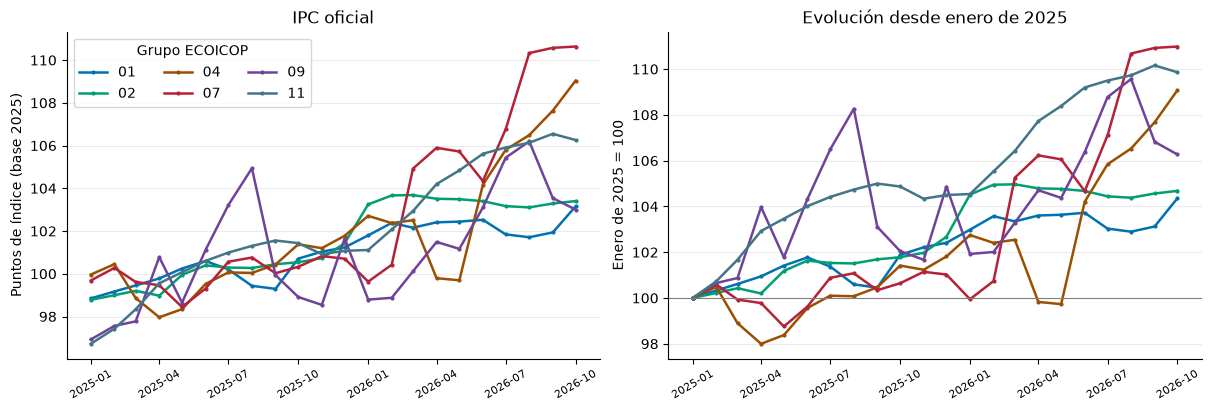

In [19]:
estadisticos = panel.describe().T.rename(columns={
    "count": "meses", "mean": "media", "std": "desv. típica", "min": "mínimo", "max": "máximo",
})
estadisticos.insert(0, "Categoría", estadisticos.index.map(GRUPOS))
display(estadisticos.round(3))
reescalado = panel.div(panel.iloc[0]).mul(100)
extremos = pd.DataFrame({
    "índice en enero de 2025": panel.iloc[0],
    "índice en octubre de 2026": panel.iloc[-1],
    "cambio entre extremos (%)": reescalado.iloc[-1].sub(100),
})
extremos.insert(0, "Categoría", extremos.index.map(GRUPOS))
display(extremos.round(3))

fechas = MESES.to_timestamp()
colores = dict(zip(GRUPOS, ["#0072B2", "#009E73", "#9C4F00", "#B52237", "#70439B", "#427687"]))

def rotular_meses(eje):
    eje.set_xticks(fechas[::3])
    eje.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    eje.grid(axis="y", alpha=0.25)
    eje.spines[["top", "right"]].set_visible(False)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, layout="constrained")
for c in GRUPOS:
    ejes[0].plot(fechas, panel[c], color=colores[c], label=c, lw=1.8, marker=".", ms=4)
    ejes[1].plot(fechas, reescalado[c], color=colores[c], label=c, lw=1.8, marker=".", ms=4)
ejes[0].set(title="IPC oficial", ylabel="Puntos de índice (base 2025)")
ejes[1].set(title="Evolución desde enero de 2025", ylabel="Enero de 2025 = 100")
ejes[1].axhline(100, color="0.5", linewidth=0.8)
for eje in ejes:
    rotular_meses(eje)
    eje.tick_params(axis="x", labelrotation=30, labelsize=8)
ejes[0].legend(ncols=3, title="Grupo ECOICOP", loc="upper left")
plt.show()

## 6. Variación mensual y movimientos atípicos

La tasa mensual se calcula como `100 × (índice del mes / índice del mes anterior − 1)`. Enero de 2025 queda sin tasa al ser el primer mes de la ventana. Al reindexar antes de calcular, también queda sin tasa cualquier par que incluya un índice ausente o no apto.

Se marcan como atípicas las tasas estrictamente fuera de los límites `Q1 − 1,5 × RIC` y `Q3 + 1,5 × RIC`, con RIC = Q3 − Q1, por grupo y con cuartiles interpolados linealmente. Se omite el criterio para grupos con menos de cuatro tasas observadas o un RIC igual a cero. El umbral es descriptivo y una tasa señalada puede corresponder a un cambio real. La muestra corta limita el estudio de la estacionalidad y la atribución de causas. Todos los movimientos válidos se conservan.

,Categoría,tasas calculables,media (%),desv. típica (p. p.),mínimo (%),máximo (%),tasas no calculables tras el primer mes
codigo,,,,,,,
01,Alimentos y bebidas no alcohólicas,21.0,0.205,0.519,-0.767,1.426,0
02,Bebidas alcohólicas y tabaco,21.0,0.219,0.468,-0.228,1.794,0
04,"Vivienda, agua, electricidad, gas y otros comb...",21.0,0.423,1.359,-2.648,4.487,0
07,Transporte,21.0,0.507,1.428,-1.310,4.480,0
09,"Actividades recreativas, deporte y cultura",21.0,0.311,2.084,-4.766,3.150,0
11,Restaurantes y servicios de alojamiento,21.0,0.450,0.460,-0.509,1.233,0


,Q1 (%),Q3 (%),RIC (p. p.),límite inferior (%),límite superior (%),tasas señaladas
codigo,,,,,,
01,-0.131,0.349,0.480,-0.850,1.069,2
02,-0.058,0.220,0.278,-0.475,0.636,3
04,-0.098,0.946,1.044,-1.664,2.512,2
07,-0.161,0.878,1.039,-1.720,2.436,2
09,-0.520,1.914,2.433,-4.170,5.564,1
11,0.211,0.743,0.533,-0.588,1.542,0


,codigo,categoria,mes,indice_anterior,indice_actual,variacion_pct
0,01,Alimentos y bebidas no alcohólicas,2025-10,99.293,100.709,1.426
1,01,Alimentos y bebidas no alcohólicas,2026-10,101.934,103.154,1.197
2,02,Bebidas alcohólicas y tabaco,2025-05,98.976,99.950,0.984
3,02,Bebidas alcohólicas y tabaco,2025-12,100.731,101.425,0.689
4,02,Bebidas alcohólicas y tabaco,2026-01,101.425,103.245,1.794
5,04,"Vivienda, agua, electricidad, gas y otros comb...",2026-04,102.507,99.793,-2.648
6,04,"Vivienda, agua, electricidad, gas y otros comb...",2026-06,99.695,104.168,4.487
7,07,Transporte,2026-03,100.423,104.922,4.480
8,07,Transporte,2026-08,106.766,110.330,3.338
9,09,"Actividades recreativas, deporte y cultura",2025-09,104.939,99.938,-4.766


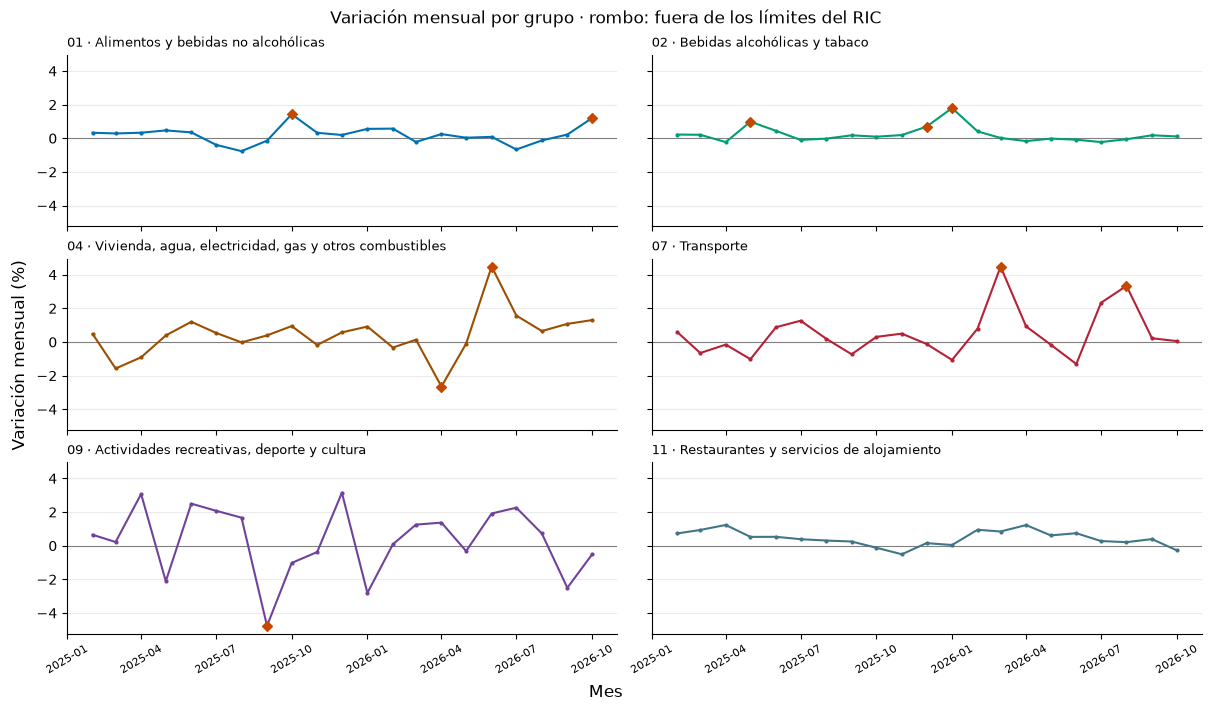

In [22]:
tasas = panel.pct_change(fill_method=None).mul(100)
resumen_tasas = tasas.agg(["count", "mean", "std", "min", "max"]).T.rename(columns={
    "count": "tasas calculables", "mean": "media (%)", "std": "desv. típica (p. p.)",
    "min": "mínimo (%)", "max": "máximo (%)",
})
resumen_tasas["tasas no calculables tras el primer mes"] = tasas.iloc[1:].isna().sum()
resumen_tasas.insert(0, "Categoría", resumen_tasas.index.map(GRUPOS))
display(resumen_tasas.round(3))

q1 = tasas.quantile(0.25, interpolation="linear")
q3 = tasas.quantile(0.75, interpolation="linear")
ric = q3 - q1
aplicar_ric = tasas.count().ge(4) & ric.gt(0)
limite_inferior = (q1 - 1.5 * ric).where(aplicar_ric)
limite_superior = (q3 + 1.5 * ric).where(aplicar_ric)
fuera = tasas.lt(limite_inferior) | tasas.gt(limite_superior)

display(pd.DataFrame({
    "Q1 (%)": q1,
    "Q3 (%)": q3,
    "RIC (p. p.)": ric,
    "límite inferior (%)": limite_inferior,
    "límite superior (%)": limite_superior,
    "tasas señaladas": fuera.sum(),
}).round(3))

atipicos = (
    tasas.where(fuera).stack().dropna().rename("variacion_pct").reset_index()
    .sort_values(["codigo", "mes"], ignore_index=True)
)
if atipicos.empty:
    print("El criterio RIC no señala movimientos en los grupos evaluables.")
else:
    atipicos["categoria"] = atipicos["codigo"].map(GRUPOS)
    atipicos["indice_anterior"] = [panel.loc[m - 1, c] for m, c in zip(atipicos["mes"], atipicos["codigo"])]
    atipicos["indice_actual"] = [panel.loc[m, c] for m, c in zip(atipicos["mes"], atipicos["codigo"])]
    columnas_tabla = ["codigo", "categoria", "mes", "indice_anterior", "indice_actual", "variacion_pct"]
    precision = {"indice_anterior": 3, "indice_actual": 3, "variacion_pct": 3}
    display(atipicos[columnas_tabla].round(precision))

fig, ejes = plt.subplots(3, 2, figsize=(12, 7), sharex=True, sharey=True, layout="constrained")
fig.supxlabel("Mes")
fig.supylabel("Variación mensual (%)")
for eje, c in zip(ejes.flat, GRUPOS):
    eje.axhline(0, color="0.5", linewidth=0.8)
    eje.plot(fechas, tasas[c], color=colores[c], linewidth=1.5, marker=".", markersize=4)
    mascara = fuera[c].to_numpy()
    eje.scatter(fechas[mascara], tasas.loc[mascara, c], marker="D", s=25, color="#C64800", zorder=3)
    eje.set_title(f"{c} · {GRUPOS[c]}", loc="left", fontsize=9)
    rotular_meses(eje)
    eje.tick_params(axis="x", labelrotation=30, labelsize=8)
fig.suptitle("Variación mensual por grupo · rombo: fuera de los límites del RIC", fontsize=12)
plt.show()

## 7. Resultados y conclusiones

La comparación cuantifica el paso de la exportación a la vista de análisis. Los cambios de tipo permiten medir la calidad y calcular indicadores en memoria. Los casos dudosos siguen visibles en los diagnósticos. Los resultados son una evidencia del EDA para la Actividad 1. La ficha de entrega y el pipeline de limpieza persistente corresponden al trabajo de la actividad que continúa después de este cuaderno.

In [49]:
n_esperadas = panel.size
n_con_registro = int(presencia.sum().sum())
n_validas = int(panel.count().sum())
n_tasas = int(tasas.count().sum())
n_filas_problema = int(filas_con_problemas.sum())

display(pd.DataFrame({
    "Etapa": ["Exportación leída", "Filas que pasan los filtros", "Combinaciones únicas con registro",
              "Combinaciones aptas para analizar el índice", "Tasas mensuales calculables"],
    "Observaciones": [len(bronze), len(muestra), n_con_registro, n_validas, n_tasas],
}))

def porcentaje(numero):
    return f"{numero:+.2f}".replace(".", ",") + " %"

conclusiones = [
    f"- **Cobertura.** Hay **{n_con_registro} de {n_esperadas}** combinaciones con registro y "
    f"**{n_validas}** con un índice apto. Se obtienen **{n_tasas} de "
    f"{len(GRUPOS) * (len(MESES) - 1)}** tasas mensuales posibles dentro de la ventana.",
    f"- **Calidad.** El CSV contiene **{int(nulos.sum().sum())}** celdas ausentes, "
    f"**{int(bronze.duplicated().sum())}** filas exactas adicionales y **{n_filas_problema}** filas "
    f"con incidencias de formato o dominio. La selección contiene **{len(recuento_duplicados)}** claves repetidas.",
]
cambios = extremos["cambio entre extremos (%)"].dropna().sort_values(ascending=False)
if not cambios.empty:
    orden = ", ".join(f"{GRUPOS[c]} ({porcentaje(tasa)})" for c, tasa in cambios.items())
    conclusiones.append(f"- **Cambio de enero de 2025 a octubre de 2026**, por orden descendente: {orden}.")

tasas_observadas = tasas.stack().dropna()
if not tasas_observadas.empty:
    mes_min, codigo_min = tasas_observadas.idxmin()
    mes_max, codigo_max = tasas_observadas.idxmax()
    conclusiones.append(
        f"- **Movimientos mensuales.** El mínimo es {porcentaje(tasas_observadas.min())} en "
        f"{GRUPOS[codigo_min]}, {mes_min:%Y-%m}, y el máximo es "
        f"{porcentaje(tasas_observadas.max())} en {GRUPOS[codigo_max]}, {mes_max:%Y-%m}. "
        f"El criterio RIC señala **{len(atipicos)}** movimientos."
    )
if n_validas == n_esperadas:
    conclusiones.append(
        "- **Viabilidad.** La muestra permite comparar los seis grupos de forma mensual para el prototipo. "
        "Para estimar la inflación de un hogar harán falta sus pesos de gasto y una correspondencia explícita "
        "con los grupos del INE. Los índices nacionales agregados tienen un alcance limitado para reproducir "
        "precios locales o gastos individuales."
    )
else:
    conclusiones.append(
        "- **Viabilidad.** La comparación mensual queda limitada a los índices aptos. Hay que revisar "
        "los meses sin registro o sin valor válido antes de utilizar la muestra completa en el prototipo."
    )

display(Markdown("\n".join(conclusiones)))

,Etapa,Observaciones
0,Exportación leída,132
1,Filas que pasan los filtros,132
2,Combinaciones únicas con registro,132
3,Combinaciones aptas para analizar el índice,132
4,Tasas mensuales calculables,126


- **Cobertura.** Hay **132 de 132** combinaciones con registro y **132** con un índice apto. Se obtienen **126 de 126** tasas mensuales posibles dentro de la ventana.
- **Calidad.** El CSV contiene **0** celdas ausentes, **0** filas exactas adicionales y **0** filas con incidencias de formato o dominio. La selección contiene **0** claves repetidas.
- **Cambio de enero de 2025 a octubre de 2026**, por orden descendente: Transporte (+10,98 %), Restaurantes y servicios de alojamiento (+9,86 %), Vivienda, agua, electricidad, gas y otros combustibles (+9,08 %), Actividades recreativas, deporte y cultura (+6,27 %), Bebidas alcohólicas y tabaco (+4,68 %), Alimentos y bebidas no alcohólicas (+4,36 %).
- **Movimientos mensuales.** El mínimo es -4,77 % en Actividades recreativas, deporte y cultura, 2025-09, y el máximo es +4,49 % en Vivienda, agua, electricidad, gas y otros combustibles, 2026-06. El criterio RIC señala **10** movimientos.
- **Viabilidad.** La muestra permite comparar los seis grupos de forma mensual para el prototipo. Para estimar la inflación de un hogar harán falta sus pesos de gasto y una correspondencia explícita con los grupos del INE. Los índices nacionales agregados tienen un alcance limitado para reproducir precios locales o gastos individuales.